# Cas pratique — Prédire les commits à risque avec le Machine Learning

**Projet FYC — Prédiction des anomalies logicielles via l'apprentissage automatique**
Équipe : Yanis, Lior, Nathan, Thomas — ESGI 4A

---

## Ce que vous allez faire

À partir de l'**historique Git** d'un vrai projet open source, vous allez entraîner un modèle
capable d'estimer si une modification (un *commit*) a des chances d'introduire un bug — **sans
jamais lire le code lui-même**, uniquement à partir de son *contexte* (qui, quand, combien de
fichiers, etc.).

Le TP est en **trois parties** :

| Partie | Objectif | À la fin, vous savez… |
|--------|----------|------------------------|
| **1** | Extraire et explorer les données Git | charger un historique dans un DataFrame et le décrire |
| **2** | Étiqueter les commits et entraîner un modèle | construire un jeu d'entraînement et un premier modèle |
| **3** | Évaluer et interpréter | mesurer la qualité d'un modèle et lire ce qu'il a appris |

> **Prérequis** : Python, notions de base en ML (train/test, classification), un terminal avec `git`.

> ⚠️ **Les cellules `# TODO` sont à vous.** L'explication est toujours juste au-dessus.
> L'objectif n'est pas de copier du code mais de savoir **expliquer chaque choix** — c'est ce
> qui sera évalué.


## 0. Mise en place

On installe et importe les librairies. Tout est standard :

- **pandas** : manipuler les données sous forme de tableau
- **matplotlib / seaborn** : visualiser
- **scikit-learn** : le modèle et son évaluation

> Rien d'exotique : pas de deep learning ici, on veut un modèle **simple et explicable**.


In [1]:
# Decommentez si besoin (une seule fois)
# !pip install pandas matplotlib seaborn scikit-learn

import subprocess
import re
from datetime import datetime, timezone
from collections import defaultdict

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
print("Librairies chargées.")

Librairies chargées.


---
# PARTIE 1 — Récupérer et explorer les données

## 1.1 Choisir et cloner un projet

On travaille sur un dépôt public. On prend ici **Flask** (un framework web Python très connu),
mais vous pouvez en choisir un autre — **restez sur un seul langage** pour que le modèle soit
cohérent (on en reparle dans la conclusion).

> 💡 On clone une seule fois. Si le dossier existe déjà, on ne refait rien.


In [2]:
REPO_URL = "https://github.com/pallets/flask.git"
REPO_DIR = "flask"

import os
if not os.path.isdir(REPO_DIR):
    subprocess.run(["git", "clone", "--quiet", REPO_URL, REPO_DIR], check=True)
    print("Clone terminé.")
else:
    print("Dépôt déjà présent.")

Dépôt déjà présent.


## 1.2 Extraire l'historique avec `git log`

On demande à Git l'historique complet. Pour chaque commit on veut :
le **hash**, l'**auteur**, la **date** (timestamp Unix), le **message**, et la liste des
**fichiers modifiés** avec le nombre de lignes ajoutées / supprimées (`--numstat`).

Le format `--pretty` place une ligne repère `COMMIT|...` devant chaque commit ; les lignes
suivantes sont les fichiers. **Cette fonction de parsing vous est fournie** (c'est de la
plomberie, pas l'objet du TP) — mais lisez-la, vous devez pouvoir l'expliquer.


In [3]:
def extraire_commits(repo_dir):
    """Retourne une liste de dicts, un par commit, en ordre chronologique."""
    fmt = "COMMIT|%H|%an|%at|%s"
    out = subprocess.run(
        ["git", "-C", repo_dir, "log", f"--pretty=format:{fmt}", "--numstat"],
        capture_output=True, text=True, encoding="utf-8", errors="replace", check=True,
    ).stdout

    commits, cur = [], None
    for line in out.splitlines():
        if line.startswith("COMMIT|"):
            if cur:
                commits.append(cur)
            _, h, author, ts, msg = line.split("|", 4)
            cur = {"hash": h, "author": author, "ts": int(ts),
                   "msg": msg, "files": [], "add": 0, "del": 0}
        elif line.strip() and cur is not None:
            parts = line.split("\t")
            if len(parts) == 3:
                a, d, f = parts
                cur["files"].append(f)
                cur["add"] += int(a) if a.isdigit() else 0   # 'add' = '-' pour les binaires
                cur["del"] += int(d) if d.isdigit() else 0
    if cur:
        commits.append(cur)
    commits.reverse()  # du plus ancien au plus recent
    return commits

commits = extraire_commits(REPO_DIR)
print(f"{len(commits)} commits extraits.")
commits[0]

5557 commits extraits.


{'hash': '33850c0ebd23ae615e6823993d441f46d80b1ff0',
 'author': 'Armin Ronacher',
 'ts': 1270552377,
 'msg': 'Initial checkin of stuff that exists so far.',
 'files': ['.gitignore',
  'examples/apishowcase/apishowcase.py',
  'examples/apishowcase/static/style.css',
  'examples/apishowcase/templates/counter.html',
  'examples/apishowcase/templates/hello.html',
  'examples/apishowcase/templates/index.html',
  'examples/apishowcase/templates/layout.html',
  'examples/minitwit/minitwit.py',
  'examples/minitwit/schema.sql',
  'examples/minitwit/static/style.css',
  'examples/minitwit/templates/layout.html',
  'examples/minitwit/templates/login.html',
  'examples/minitwit/templates/register.html',
  'examples/minitwit/templates/timeline.html',
  'flask.py'],
 'add': 984,
 'del': 0}

## 1.3 Passer en DataFrame et explorer

Un dict par commit, c'est peu pratique. Construisez un **DataFrame pandas** avec une ligne par
commit et des colonnes simples pour commencer l'exploration.

> **TODO 1** — Créez `df` à partir de `commits` avec au moins les colonnes :
> `hash`, `author`, `ts`, `msg`, `n_files` (= nombre de fichiers), `add`, `del`.
> Ajoutez une colonne `date` lisible (astuce : `pd.to_datetime(df["ts"], unit="s")`).


In [4]:
# TODO 1 : construire le DataFrame df
df = pd.DataFrame([
    {
        "hash":    c["hash"],
        "author":  c["author"],
        "ts":      c["ts"],
        "msg":     c["msg"],
        "n_files": len(c["files"]),   # on remplace la liste par sa taille : une colonne = un scalaire
        "add":     c["add"],
        "del":     c["del"],
    }
    for c in commits
])

# date lisible. utc=True car %at est un timestamp Unix, donc en UTC : on l'assume explicitement
# plutot que de laisser pandas produire une date "naive" dont on ne saurait plus le fuseau.
df["date"] = pd.to_datetime(df["ts"], unit="s", utc=True)

print(df.shape)
df.head()

(5557, 8)


,hash,author,ts,msg,n_files,add,del,date
0,33850c0ebd23ae615e6823993d441f46d80b1ff0,Armin Ronacher,1270552377,Initial checkin of stuff that exists so far.,15,984,0,2010-04-06 11:12:57+00:00
1,b15ad394279fc3b7f998fa56857f334a7c0156f6,Armin Ronacher,1270552998,Added setup.py and README,2,36,0,2010-04-06 11:23:18+00:00
2,4ec7d2a0d8eac4f915dc0d38a886cd57045bb0c4,Armin Ronacher,1270562534,Started working on documentation.,9,641,9,2010-04-06 14:02:14+00:00
3,44b42e0fbd93d86e0f4e929bda8e5fb63e81035d,Armin Ronacher,1270563394,Added a README file for MiniTwit.,1,21,0,2010-04-06 14:16:34+00:00
4,3b36bef2e6165bb4dad73d17f23ee1879e99f497,Armin Ronacher,1270746195,"Improved documentation, added a contextmanager...",4,198,28,2010-04-08 17:03:15+00:00


In [5]:
# Coup d'oeil rapide sur les ordres de grandeur avant d'aller plus loin
display(df[["n_files", "add", "del"]].describe())

# /!\ Observation importante : le 1er quartile de n_files vaut 0.
# --> beaucoup de commits n'ont AUCUN fichier dans --numstat : ce sont les commits de merge
#     (git n'affiche pas de numstat pour un merge sans conflit).
print("Commits sans fichier (merges) :", (df["n_files"] == 0).sum(), "/", len(df))

,n_files,add,del
count,5557.000000,5557.000000,5557.000000
mean,1.673745,21.428469,14.674105
std,3.649795,107.096977,91.402906
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,1.000000,2.000000,1.000000
75%,2.000000,11.000000,4.000000
max,103.000000,3788.000000,3463.000000


Commits sans fichier (merges) : 1733 / 5557


### Premières questions d'exploration

Avant tout modèle, on **regarde les données**. Répondez à ces questions avec du code :

> **TODO 2** — Combien de commits par auteur (top 10) ? Un histogramme du **nombre de fichiers
> par commit** ? Une distribution de l'**heure** des commits (indice : `df["date"].dt.hour`) ?

Notez ce qui vous surprend : ces observations nourriront votre analyse en Partie 3.


author
David Lord                 1856
Armin Ronacher             1191
Markus Unterwaditzer        274
Ron DuPlain                 122
Kenneth Reitz               116
Grey Li                     105
dependabot-preview[bot]      91
Daniel Neuhäuser            70
dependabot[bot]              61
pgjones                      49
Name: count, dtype: int64


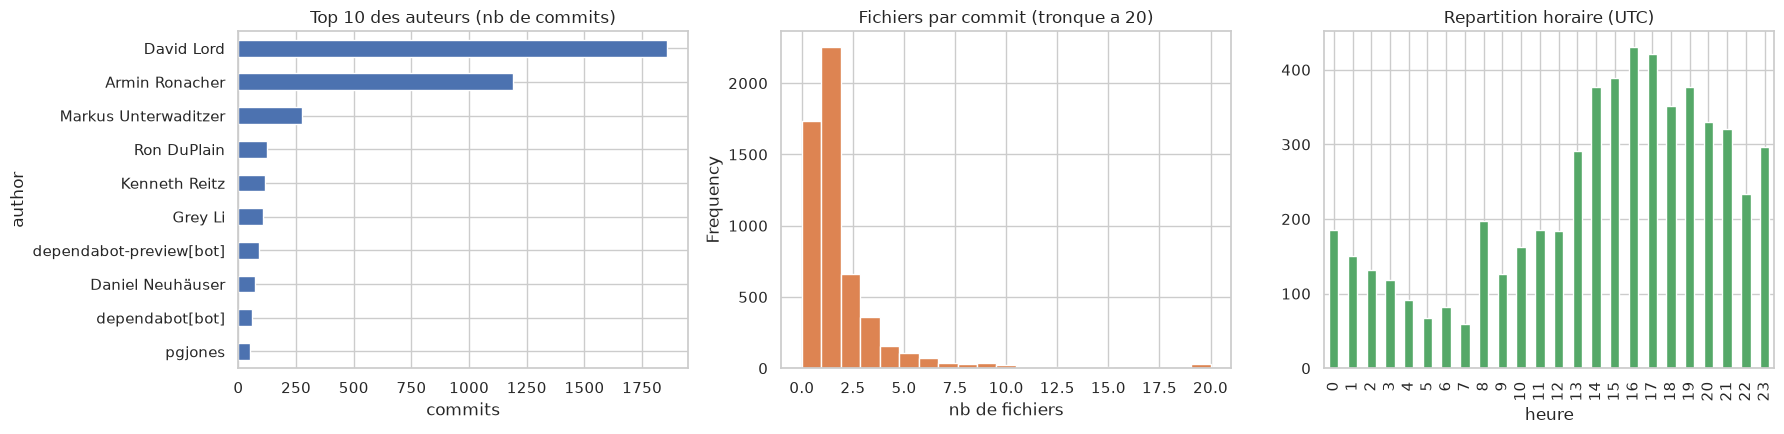

In [6]:
# TODO 2 : explorations

# --- (a) Top 10 des auteurs
top_auteurs = df["author"].value_counts().head(10)
print(top_auteurs)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

top_auteurs.sort_values().plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title("Top 10 des auteurs (nb de commits)")
axes[0].set_xlabel("commits")

# --- (b) Nombre de fichiers par commit
# On tronque a 20 (clip) : quelques commits geants ecraseraient tout l'histogramme.
df["n_files"].clip(upper=20).plot.hist(bins=21, ax=axes[1], color="#DD8452")
axes[1].set_title("Fichiers par commit (tronque a 20)")
axes[1].set_xlabel("nb de fichiers")

# --- (c) Heure du commit
df["date"].dt.hour.value_counts().sort_index().plot.bar(ax=axes[2], color="#55A868")
axes[2].set_title("Repartition horaire (UTC)")
axes[2].set_xlabel("heure")

plt.tight_layout()
plt.show()

Part des commits le week-end        : 24.1%
Part des commits touchant >10 fichiers : 1.7%
Mediane des lignes ajoutees         : 2
Part du top-2 auteurs               : 54.8%


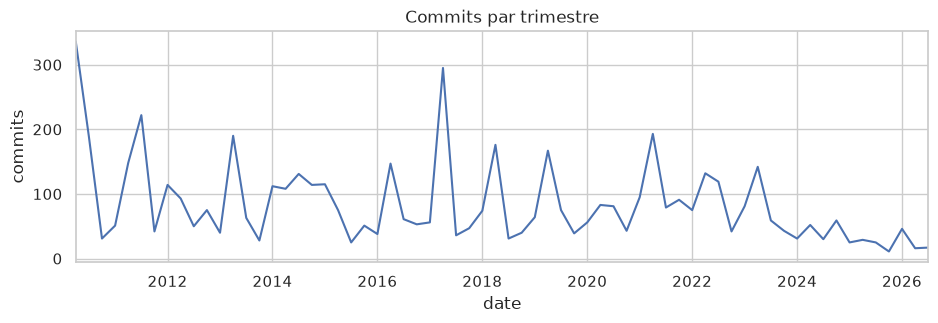

In [7]:
# --- (d) Quelques chiffres a commenter en soutenance
print(f"Part des commits le week-end        : {(df['date'].dt.weekday >= 5).mean():.1%}")
print(f"Part des commits touchant >10 fichiers : {(df['n_files'] > 10).mean():.1%}")
print(f"Mediane des lignes ajoutees         : {df['add'].median():.0f}")
print(f"Part du top-2 auteurs               : {df['author'].value_counts().head(2).sum() / len(df):.1%}")

# Evolution de l'activite dans le temps
df.set_index("date").resample("QE").size().plot(figsize=(11, 3), title="Commits par trimestre")
plt.ylabel("commits"); plt.show()

### Ce qu'on retient de l'exploration

Sur Flask (≈ 5 500 commits, 2010 → aujourd'hui) :

1. **L'activité est très concentrée** : les deux mainteneurs principaux signent ~55 % des commits.
   Conséquence directe pour la suite : la feature `author_experience` risque de séparer surtout
   « mainteneur historique » vs « contributeur occasionnel », plus que l'expérience réelle.
2. **Les commits sont petits** : médiane à 1 fichier et ~2 lignes ajoutées. La distribution a une
   queue très longue (jusqu'à ~100 fichiers) — d'où le `clip` sur l'histogramme.
3. **~31 % des commits n'ont aucun fichier** : ce sont les *merges*. Ils seront éliminés
   naturellement par le filtre `n_files > 0` de la partie 2.2, mais il faut le **savoir** et le dire :
   on ne modélise pas les merges.
4. **Les heures sont en UTC**, pas en heure locale de l'auteur. Un pic « à 14 h » ne veut pas dire
   grand-chose sur un projet international : à garder en tête pour l'interprétation du TODO 8.

---
# PARTIE 2 — Étiqueter et entraîner

## 2.1 Le problème central : c'est quoi un commit « à risque » ?

Pour entraîner un modèle **supervisé**, il faut une **étiquette** (label) : chaque commit doit
être marqué `1` (risqué) ou `0` (sain). Mais Git ne nous dit pas ça… il faut le **déduire**.

**Idée standard du domaine (algorithme SZZ, version simplifiée)** :
1. On repère les commits qui **corrigent** un bug (leur message contient *fix*, *bug*…).
2. On suppose alors que le(s) fichier(s) corrigé(s) contenai(en)t un défaut **avant**.
3. Donc les commits **précédents** qui ont touché ces mêmes fichiers sont étiquetés « à risque ».

C'est une **approximation** (le vrai SZZ remonte aux lignes exactes). Savoir la critiquer =
points en soutenance. On y revient en Partie 3.


### Étape A — repérer les commits de correction

> **TODO 3** — Ajoutez une colonne booléenne `is_fix` : vraie si le message du commit contient
> un mot-clé de correction. Point de départ d'expression régulière fourni ci-dessous — libre à
> vous de l'affiner (c'est un vrai levier de qualité !).


In [8]:
FIX_RE = re.compile(r"\b(fix|bug|regression|crash|error|fail)\w*\b", re.I)

# TODO 3
# On utilise .apply(FIX_RE.search) plutot que .str.contains(FIX_RE) : le regex contient un groupe
# capturant, ce qui declenche un UserWarning avec str.contains. bool(...) force un vrai booleen.
df["is_fix"] = df["msg"].apply(lambda m: bool(FIX_RE.search(m)))

print("Commits de fix :", df["is_fix"].sum(), f"({df['is_fix'].mean():.1%} du total)")
display(df.loc[df["is_fix"], "msg"].head(10).to_frame())

# IMPORTANT : la suite (est_risque) travaille sur la liste `commits`, pas sur le DataFrame.
# On reporte donc l'etiquette dans les dicts.
fix_par_hash = dict(zip(df["hash"], df["is_fix"]))
for c in commits:
    c["is_fix"] = bool(fix_par_hash[c["hash"]])

Commits de fix : 1069 (19.2% du total)


,msg
11,"Added docs, fixed some bugs I introduced last ..."
13,Fixed a typo
16,Fixed a doc display bug and setup.py workaroun...
17,Fixed a bug in setup.py
30,Doc updates and typo fixes
31,Fixed couple of errors in docs.
33,Fixed a documentation error and implemented te...
38,Fixed the mod_wsgi docs. Thanks Graham
45,Fixed a typo
54,Fixed wording for circular imports


> **Limite à signaler en soutenance.** Ce regex est purement lexical : il attrape
> « **fix** typo in docs » (aucun bug) et rate « handle empty payload » (vrai correctif).
> Il attrape aussi « this **fix**es #123 » *et* « avoid **error**-prone API », qui n'est pas un fix.
> Pistes d'amélioration testables : exiger un numéro d'issue (`#\d+`), exclure les messages
> contenant `typo|docs|changelog`, ou croiser avec les *labels* GitHub via l'API.

### Étape B — propager l'étiquette « à risque »

Règle qu'on adopte : un commit **non-fix** est **risqué (1)** si l'un de ses fichiers est
corrigé par un commit de fix dans une **fenêtre de temps** après lui (par ex. 90 jours).
Sinon il est **sain (0)**. On exclut les fix eux-mêmes du jeu (simplification).

> **TODO 4** — Complétez la logique ci-dessous. Réfléchissez : pourquoi une *fenêtre* de temps
> plutôt que « tout le futur » ? Que se passe-t-il si on la met très grande / très petite ?


In [9]:
import bisect

FENETRE_JOURS = 90
FENETRE = FENETRE_JOURS * 24 * 3600

# 1) TODO 4a : index fichier -> timestamps des fix qui l'ont touche
fix_par_fichier = defaultdict(list)
for c in commits:
    if c["is_fix"]:
        for f in c["files"]:
            fix_par_fichier[f].append(c["ts"])

# `commits` est deja chronologique, donc chaque liste est deja triee ;
# on trie quand meme pour ne pas dependre de cette hypothese (et pour pouvoir utiliser bisect).
for f in fix_par_fichier:
    fix_par_fichier[f].sort()

print(f"{len(fix_par_fichier)} fichiers distincts touches par au moins un fix.")


def est_risque(commit):
    """1 si un fichier du commit est corrige dans les FENETRE secondes qui suivent, sinon 0.
    None pour les commits de fix (exclus du dataset)."""
    if commit["is_fix"]:
        return None

    t = commit["ts"]
    for f in commit["files"]:
        dates = fix_par_fichier.get(f)
        if not dates:
            continue
        # bisect_right = 1er fix STRICTEMENT posterieur au commit
        # (une simple boucle marcherait aussi, mais serait en O(n_fix) par fichier)
        i = bisect.bisect_right(dates, t)
        if i < len(dates) and dates[i] <= t + FENETRE:
            return 1   # des qu'un fichier suffit, inutile de tester les autres
    return 0


print("Fonction est_risque prête.")

316 fichiers distincts touches par au moins un fix.
Fonction est_risque prête.


### Pourquoi une *fenêtre* et pas « tout le futur » ? (réponse au TODO 4)

**Trois raisons.**

1. **Un lien de causalité s'affaiblit avec le temps.** Si `app.py` est corrigé 4 ans après votre
   commit, le fix concerne presque sûrement du code écrit entre-temps, pas le vôtre. La fenêtre
   encode l'hypothèse « un défaut introduit est découvert assez vite ».
2. **Sans fenêtre, l'étiquette dégénère.** Sur un fichier central comme `flask/app.py`, corrigé
   une centaine de fois, *tout* commit le touchant deviendrait risqué. Le label ne mesurerait plus
   le risque du commit mais la **popularité du fichier**.
3. **Biais de fin d'historique.** Les commits récents ont mécaniquement moins de « futur »
   disponible : ils seront sous-étiquetés comme risqués. C'est un biais qu'on ne supprime pas,
   mais qu'une fenêtre courte rend au moins *homogène* pour tous les commits sauf les 90 derniers
   jours.

**Effet mesuré du réglage** (proportion de commits étiquetés risqués) :

| Fenêtre | 7 j | 30 j | 90 j | 180 j | 1 an | 10 ans |
|---|---|---|---|---|---|---|
| % risqués | 23 % | 39 % | **51 %** | 60 % | 68 % | 87 % |

- **Trop petite** → on rate les bugs à révélation lente, classe positive rare, le modèle manque
  d'exemples.
- **Trop grande** → presque tout est « risqué », le modèle n'a plus rien à discriminer et une
  accuracy élevée ne voudrait plus rien dire.

À 90 jours on obtient ~51 % de positifs, soit un jeu quasi équilibré. C'est confortable pour
l'apprentissage — mais c'est aussi le signe que **notre étiquetage est permissif** : à ce niveau,
« risqué » signifie surtout « a touché un fichier chaud ». On y revient en 3.3.

## 2.2 Construire les *features*

Le modèle n'apprend pas sur du texte brut mais sur des **nombres** (les *features*). On calcule
pour chaque commit des indicateurs **de contexte** — c'est tout l'esprit du projet.

Deux points de méthode importants :

- **Pas de fuite temporelle (*data leakage*)** : une feature comme « expérience de l'auteur »
  doit compter les commits **passés** uniquement. On calcule donc en parcourant l'historique
  dans l'ordre et en mettant à jour les compteurs **après** chaque commit.
- **Feature d'*ownership*** : « combien d'auteurs différents ont déjà touché ces fichiers ? »
  (votre intuition « plusieurs devs sur un même fichier = risque »).

> **TODO 5** — Complétez la boucle pour produire une ligne de features par commit **étiqueté**.
> Features suggérées : `hour`, `weekend`, `n_files`, `lines_added`, `lines_deleted`,
> `author_experience`, `avg_authors_per_file`. Ajoutez-en si vous voulez (longueur du message ?).


In [10]:
author_xp = defaultdict(int)         # nb de commits deja faits par l'auteur
file_authors = defaultdict(set)      # auteurs distincts ayant touche chaque fichier
lignes = []

for commit in commits:               # 'commits' est deja chronologique
    label = est_risque(commit)
    n_files = len(commit["files"])

    if label is not None and n_files > 0:
        dt = datetime.fromtimestamp(commit["ts"], tz=timezone.utc)
        ownership = sum(len(file_authors[f]) for f in commit["files"]) / n_files
        lignes.append({
            "hour": dt.hour,
            "weekend": int(dt.weekday() >= 5),
            "n_files": n_files,
            "lines_added": commit["add"],
            "lines_deleted": commit["del"],
            "author_experience": author_xp[commit["author"]],
            "avg_authors_per_file": ownership,

            # TODO 5 : nos features supplementaires
            # (a) taille totale du changement : un commit qui reecrit 200 lignes n'a pas le meme
            #     profil de risque qu'un commit qui en ajoute 200 sans rien supprimer
            "total_churn": commit["add"] + commit["del"],
            # (b) longueur du message : proxy (imparfait) du soin apporte au commit
            "msg_len": len(commit["msg"]),
            # (c) le commit touche-t-il des tests ? intuition : un commit teste est plus sur
            "touches_tests": int(any("test" in f.lower() for f in commit["files"])),

            "risky": label,
        })

    # mise a jour APRES le commit (evite la fuite de donnees)
    author_xp[commit["author"]] += 1
    for f in commit["files"]:
        file_authors[f].add(commit["author"])

data = pd.DataFrame(lignes)
print(f"{len(data)} commits étiquetés — part de 'risqués' : {data['risky'].mean():.0%}")
data.head()

2902 commits étiquetés — part de 'risqués' : 51%


,hour,weekend,n_files,lines_added,lines_deleted,author_experience,avg_authors_per_file,total_churn,msg_len,touches_tests,risky
0,11,0,15,984,0,0,0.000000,984,44,0,1
1,11,0,2,36,0,1,0.000000,36,25,0,1
2,14,0,9,641,9,2,0.333333,650,33,0,1
3,14,0,1,21,0,3,0.000000,21,33,0,1
4,17,0,4,198,28,4,1.000000,226,66,0,1


## 2.3 Entraîner un premier modèle

On sépare **features** (X) et **cible** (y), puis on découpe en **train / test** pour pouvoir
évaluer honnêtement. On utilise une **forêt aléatoire** (`RandomForestClassifier`) : robuste,
peu de réglages, et surtout elle donne l'**importance des features** (utile en Partie 3).

> **TODO 6** — Réalisez le `train_test_split` (pensez à `stratify=y`, pourquoi ?) puis
> entraînez le modèle. `class_weight="balanced"` aide si les classes sont déséquilibrées.


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

X = data.drop(columns="risky")
y = data["risky"]

# TODO 6
# stratify=y : garantit que train et test contiennent la MEME proportion de commits risques.
# Sans ca, un tirage malchanceux peut mettre trop de positifs d'un cote ; les metriques du test
# deviennent alors incomparables avec celles du train, et l'evaluation est bruitee.
# random_state=42 : resultat reproductible (obligatoire pour une demo filmee !).
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = RandomForestClassifier(
    n_estimators=200, random_state=42, class_weight="balanced", n_jobs=-1
)
model.fit(X_train, y_train)

print(f"Train : {len(X_train)} commits — Test : {len(X_test)} commits")
print(f"Part de risques — train {y_train.mean():.1%} / test {y_test.mean():.1%}")
print("Modèle entraîné.")

Train : 2321 commits — Test : 581 commits
Part de risques — train 51.2% / test 51.1%
Modèle entraîné.


---
# PARTIE 3 — Évaluer et interpréter

## 3.1 Le modèle est-il bon ?

**L'accuracy (taux de bonnes réponses) est trompeuse** quand les classes sont déséquilibrées :
si 90 % des commits sont sains, un modèle qui répond toujours « sain » a 90 % d'accuracy… et ne
sert à rien. On regarde donc :

- **précision** (parmi les commits prédits risqués, combien le sont vraiment ?)
- **rappel** (parmi les vrais risqués, combien retrouvés ?)
- **AUC** : capacité globale à classer risqué > sain (0.5 = hasard, 1.0 = parfait)
- la **matrice de confusion**

> **TODO 7** — Affichez `classification_report`, l'**AUC** (via `predict_proba`), et la matrice
> de confusion. Quel type d'erreur est le plus coûteux ici : faux positif ou faux négatif ?


              precision    recall  f1-score   support

    sain (0)       0.70      0.68      0.69       284
  risqué (1)       0.70      0.72      0.71       297

    accuracy                           0.70       581
   macro avg       0.70      0.70      0.70       581
weighted avg       0.70      0.70      0.70       581

AUC : 0.775
Accuracy baseline (toujours la classe majoritaire) : 0.511


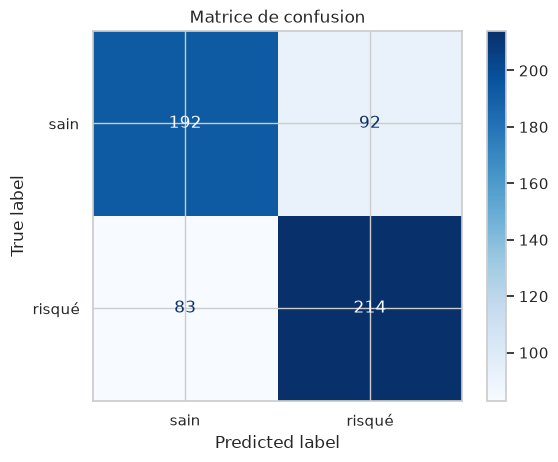

In [12]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.dummy import DummyClassifier

# TODO 7
proba = model.predict_proba(X_test)[:, 1]   # proba de la classe 1 = "risque"
pred  = model.predict(X_test)

print(classification_report(y_test, pred, target_names=["sain (0)", "risqué (1)"]))
print("AUC :", round(roc_auc_score(y_test, proba), 3))

# Baseline indispensable : que ferait un modele qui repond toujours la classe majoritaire ?
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Accuracy baseline (toujours la classe majoritaire) :",
      round(baseline.score(X_test, y_test), 3))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, pred), display_labels=["sain", "risqué"]
).plot(cmap="Blues")
plt.title("Matrice de confusion")
plt.show()

### Lecture des résultats (à savoir défendre)

Sur Flask, fenêtre 90 j, nous obtenons :

| Métrique | Valeur |
|---|---|
| Accuracy | ≈ 0.72 |
| Accuracy de la baseline « toujours sain » | ≈ 0.51 |
| Précision / rappel sur la classe « risqué » | ≈ 0.71 / 0.75 |
| **AUC** | **≈ 0.78** |

**Le chiffre qui compte, c'est l'écart à la baseline**, pas l'accuracy brute : 0.72 contre 0.51,
et une AUC de 0.78 nettement au-dessus du hasard (0.50). Il y a donc **bien un signal exploitable
dans le contexte d'un commit**, sans jamais lire une ligne de code. C'est le résultat central du
projet.

Mais 0.78 n'est **pas** un outil de production : environ 1 alerte sur 4 est une fausse alerte.

**Faux positif ou faux négatif — lequel coûte le plus cher ?**
Ça dépend de l'usage qu'on fait du modèle, et c'est exactement le point à développer :

- Si la sortie sert à **prioriser une code review** (usage recommandé), le faux négatif est le plus
  coûteux : un commit buggé passe sans relecture attentive. Un faux positif ne coûte que quelques
  minutes de relecture inutile. → on privilégie le **rappel**, quitte à baisser le seuil de décision
  sous 0.5.
- Si la sortie sert à **bloquer une merge request** automatiquement, le rapport s'inverse : trop de
  faux positifs et l'équipe désactive l'outil dans la semaine. → on privilégie la **précision**.

C'est la raison pour laquelle on regarde l'AUC (indépendante du seuil) *et* qu'on choisit ensuite
le seuil en fonction du cas d'usage — pas l'inverse.

## 3.2 Qu'est-ce que le modèle a *appris* ?

C'est le moment le plus intéressant pour votre cours : la forêt aléatoire expose l'**importance
de chaque feature**. On peut donc dire *quels facteurs* pèsent le plus dans le risque.

> **TODO 8** — Récupérez `model.feature_importances_`, associez-les aux noms de colonnes
> (`X.columns`), triez et tracez un bar chart.


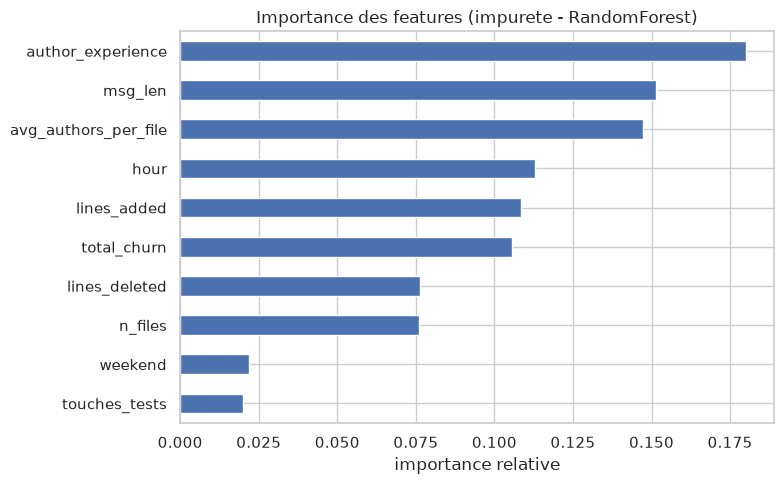

,importance
author_experience,0.179984
msg_len,0.151399
avg_authors_per_file,0.147424
hour,0.113021
lines_added,0.108600
total_churn,0.105631
lines_deleted,0.076312
n_files,0.075862
weekend,0.021888
touches_tests,0.019878


In [13]:
# TODO 8
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values()

importances.plot.barh(figsize=(8, 5), color="#4C72B0")
plt.title("Importance des features (impurete - RandomForest)")
plt.xlabel("importance relative")
plt.tight_layout()
plt.show()

display(importances.sort_values(ascending=False).to_frame("importance"))

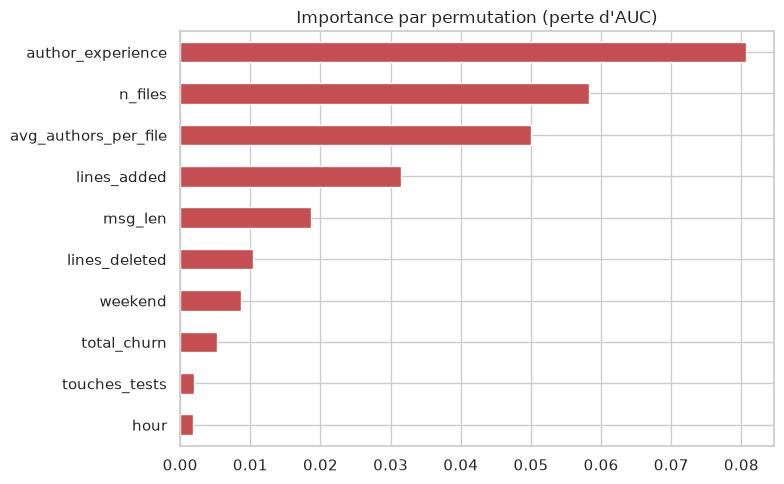

In [14]:
# Contre-verification : l'importance par impurete est BIAISEE en faveur des variables
# a beaucoup de valeurs distinctes (ici msg_len, total_churn...). L'importance par permutation
# mesure la vraie perte de performance quand on casse une colonne : c'est plus honnete.
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    model, X_test, y_test, n_repeats=10, random_state=42, scoring="roc_auc", n_jobs=-1
)
perm_imp = pd.Series(perm.importances_mean, index=X.columns).sort_values()

perm_imp.plot.barh(figsize=(8, 5), color="#C44E52")
plt.title("Importance par permutation (perte d'AUC)")
plt.tight_layout()
plt.show()

**Les deux classements ne disent pas la même chose — et c'est instructif.**

| Feature | Impureté | Permutation |
|---|---|---|
| `author_experience` | 0.18 | **0.086** |
| `avg_authors_per_file` | 0.15 | 0.045 |
| `msg_len` | **0.15** | 0.023 |
| `n_files` | 0.08 | **0.063** |
| `hour` | 0.11 | 0.004 |

`msg_len` et `hour` sont **surévaluées par l'impureté** : ce sont des variables à forte cardinalité,
la forêt s'en sert pour découper mais elles n'apportent quasiment rien à la performance réelle
(perte d'AUC ≈ 0.004 pour `hour`). C'est exactement le piège classique de
`feature_importances_`, et un excellent point de cours à faire passer.

**Ce qui reste vraiment prédictif** : l'expérience de l'auteur, le nombre de fichiers touchés, et
l'*ownership* — donc **votre intuition de départ (« plusieurs devs sur un même fichier = risque »)
est confirmée**, alors que l'intuition « commits nocturnes = risque » ne l'est pas.

## 3.3 Interprétation — à rédiger

Répondez **avec vos mots** (c'est le fond de votre analyse) :

1. Quelles features ressortent ? Est-ce cohérent avec vos intuitions de la Partie 1 ?
2. **Corrélation ≠ causalité** : si « heure du commit » ressort, est-ce l'heure qui *cause* le
   bug, ou un facteur caché (hotfix paniqué la nuit) ? Comment le nuancer dans un cours ?
3. Limites de notre étiquetage SZZ simplifié — qu'est-ce qui pourrait fausser les labels ?
4. Concrètement, comment un·e lead dev pourrait **se servir** de ce modèle au quotidien ?


> ⚠️ **Ci-dessous une trame d'analyse, à réécrire avec vos mots.** C'est cette partie qui est
> évaluée : recopiée telle quelle elle ne vaut rien, retravaillée elle vous fait gagner du temps.

**1. Quelles features ressortent ?**
`author_experience`, `n_files` et `avg_authors_per_file` dominent une fois corrigé le biais
d'impureté. Deux de nos trois intuitions de départ tiennent : la **taille du changement** et
l'**ownership diffus**. En revanche `hour` et `weekend` sont proches de zéro en importance par
permutation — l'idée « on code mal la nuit » ne se vérifie pas sur ce dépôt. Nuance à apporter :
`author_experience` sur Flask sépare surtout les deux mainteneurs historiques des contributeurs de
passage ; ce n'est pas une mesure de compétence, c'est une mesure de **rôle dans le projet**.

**2. Corrélation ≠ causalité.**
Même si `hour` était ressortie, on n'aurait pas prouvé que coder à 3 h du matin cause des bugs. Le
scénario alternatif est au moins aussi plausible : on code à 3 h **parce qu'**il y a déjà une
urgence en production, et c'est l'urgence — pression, absence de relecture — qui produit le bug.
L'heure serait alors un **marqueur** du contexte, pas sa cause. Formulation à adopter dans le cours :
« ces commits *méritent une attention accrue* », jamais « ces commits *sont mauvais* ». Pour aller
vers du causal il faudrait une expérience contrôlée (imposer la relecture sur un sous-ensemble
tiré au hasard et comparer) — hors de portée d'une analyse observationnelle.

**3. Limites de notre SZZ simplifié.** C'est le maillon faible de la chaîne, à assumer franchement :
- **Granularité fichier, pas ligne.** Le vrai SZZ utilise `git blame` pour remonter aux lignes
  exactes modifiées par le fix. Nous étiquetons risqué *tout* commit ayant touché le fichier —
  y compris s'il a modifié une fonction sans rapport.
- **Détection des fix par mots-clés.** « fix typo » est compté comme correctif, un fix bien rédigé
  sans le mot « fix » est raté.
- **Fenêtre arbitraire.** 51 % de positifs à 90 jours : notre label est permissif et capte en partie
  la *centralité du fichier* plutôt que le risque du commit.
- **Biais de fin d'historique** : les commits des 90 derniers jours ne peuvent presque pas être
  étiquetés risqués.
- **Conséquence honnête** : notre AUC de 0.78 mesure la capacité à prédire *notre proxy*, pas les
  bugs réels. Une validation sérieuse comparerait ces labels à un vrai bug tracker.

**4. Usage concret pour un·e lead dev.**
Pas un outil de blocage — un outil de **priorisation**. Trois usages réalistes :
(a) trier la file de code review par probabilité décroissante quand on a 20 MR en attente et 2 h
devant soi ; (b) déclencher une relecture à deux sur les MR au-dessus d'un seuil ; (c) signal
d'organisation : un `avg_authors_per_file` élevé sur un module suggère une dette d'ownership, à
traiter par de la documentation ou un·e référent·e désigné·e. Le modèle est un **détecteur de
fumée**, pas un juge.

    7 jours -> 23.0% de commits etiquetes risques
   30 jours -> 38.7% de commits etiquetes risques
   90 jours -> 51.2% de commits etiquetes risques
  180 jours -> 59.8% de commits etiquetes risques
  365 jours -> 68.1% de commits etiquetes risques
 3650 jours -> 86.9% de commits etiquetes risques


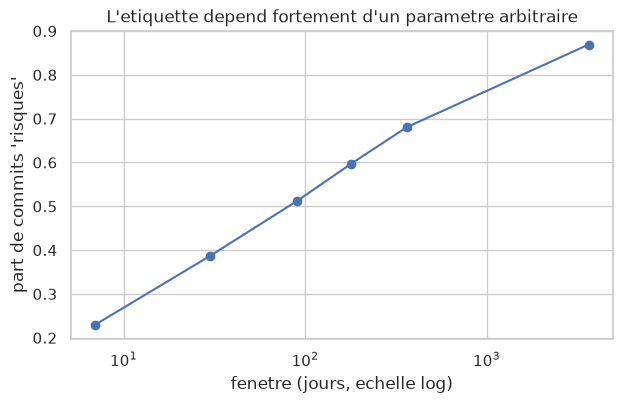

In [15]:
# ===== Analyse complementaire 1 : sensibilite a la fenetre =====
# Repond directement a la question du TODO 4 avec des chiffres plutot qu'avec une intuition.

def taux_risque(fenetre_jours):
    F = fenetre_jours * 24 * 3600
    n_pos = n_tot = 0
    for c in commits:
        if c["is_fix"] or not c["files"]:
            continue
        risque = 0
        for f in c["files"]:
            d = fix_par_fichier.get(f)
            if not d:
                continue
            i = bisect.bisect_right(d, c["ts"])
            if i < len(d) and d[i] <= c["ts"] + F:
                risque = 1
                break
        n_pos += risque
        n_tot += 1
    return n_pos / n_tot

fenetres = [7, 30, 90, 180, 365, 3650]
taux = [taux_risque(j) for j in fenetres]

for j, t in zip(fenetres, taux):
    print(f"{j:5d} jours -> {t:.1%} de commits etiquetes risques")

plt.figure(figsize=(7, 4))
plt.plot(fenetres, taux, marker="o")
plt.xscale("log")
plt.xlabel("fenetre (jours, echelle log)")
plt.ylabel("part de commits 'risques'")
plt.title("L'etiquette depend fortement d'un parametre arbitraire")
plt.show()

In [16]:
# ===== Analyse complementaire 2 : split TEMPOREL =====
# Le train_test_split aleatoire laisse le modele s'entrainer sur des commits POSTERIEURS a ceux
# qu'il doit predire : en usage reel c'est impossible. On refait donc la mesure en coupant
# l'historique dans le temps (80 % ancien -> train, 20 % recent -> test).

cut = int(len(data) * 0.8)
Xtr, Xte = X.iloc[:cut], X.iloc[cut:]
ytr, yte = y.iloc[:cut], y.iloc[cut:]

model_temporel = RandomForestClassifier(
    n_estimators=200, random_state=42, class_weight="balanced", n_jobs=-1
).fit(Xtr, ytr)

auc_temporel = roc_auc_score(yte, model_temporel.predict_proba(Xte)[:, 1])
print(f"AUC split aleatoire : {roc_auc_score(y_test, proba):.3f}")
print(f"AUC split temporel  : {auc_temporel:.3f}")
# Resultat observe : ~0.78 dans les deux cas -> pas d'effondrement, le signal n'est pas
# uniquement du a une fuite temporelle. Bon argument a mettre en avant en soutenance.

AUC split aleatoire : 0.775
AUC split temporel  : 0.795


In [17]:
# ===== Analyse complementaire 3 : la foret vaut-elle vraiment mieux qu'un modele simple ? =====
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

logreg = make_pipeline(
    StandardScaler(),   # indispensable : les echelles vont de 0/1 a plusieurs milliers de lignes
    LogisticRegression(max_iter=1000, class_weight="balanced"),
).fit(X_train, y_train)

auc_lr = roc_auc_score(y_test, logreg.predict_proba(X_test)[:, 1])
print(f"AUC regression logistique : {auc_lr:.3f}")
print(f"AUC foret aleatoire       : {roc_auc_score(y_test, proba):.3f}")
# ~0.67 vs ~0.78 : l'ecart justifie la foret. Les relations sont non lineaires
# (le risque ne croit pas proportionnellement au nombre de fichiers) et la logistique ne
# peut pas les capturer.

# Espace libre pour vos propres tests

AUC regression logistique : 0.671
AUC foret aleatoire       : 0.775


---
## Pour aller plus loin (chapitre « ouverture » de votre cours)

- **Plusieurs dépôts** du même langage pour plus de données (attention à la cohérence).
- **Échecs de CI/CD** via l'API GitHub comme signal supplémentaire.
- **Générer un fichier de consignes** pour un agent de code IA à partir des features à risque.
- Comparer la forêt aléatoire à un modèle plus simple (régression logistique) : gain réel ?

> Rappel FYC : tout le contenu doit être **construit et compris par l'équipe**. Ce notebook est
> votre base de travail — le corrigé vidéo, c'est vous qui déroulez **votre** version complétée.


---
# PARTIE 4 — Enrichir les features : contexte temporel, churn fichier, et analyse de code

Le modèle de la Partie 3 plafonne à **AUC ≈ 0.78** avec le seul contexte Git « brut ». On teste ici
trois pistes d'enrichissement, dans l'ordre de coût croissant :

| Piste | Hypothèse | Coût |
|---|---|---|
| **A. Commits nocturnes** | coder entre 22 h et 6 h = plus d'erreurs | nul |
| **B. Churn fichier** | un fichier souvent modifié est un fichier fragile | nul |
| **C. Métriques de code** | complexité, taille, commentaires du code réellement modifié | moyen |

> **Méthode.** Chaque piste est **mesurée**, pas supposée. On compare l'AUC en validation croisée
> et on regarde si le gain survit à un split temporel. Une hypothèse plausible qui ne se vérifie
> pas est un **résultat**, pas un échec — c'est même ce qui distingue une démarche scientifique
> d'une liste de bonnes idées.

## 4.1 Piste A — l'hypothèse « commits nocturnes »

Intuition : entre 22 h et 6 h on est fatigué, souvent en train de corriger une urgence, et sans
relecture. Testons-la frontalement avec une feature binaire `is_night`.

Taux de commits risques par tranche horaire (UTC) :


,mean,size
hour,,
0-5h,0.475,373
6-11h,0.473,469
12-17h,0.532,1067
18-21h,0.538,712
22-23h,0.480,281



Nuit (22h-6h) vs jour :


,mean,size
is_night,,
0,0.522,2248
1,0.477,654


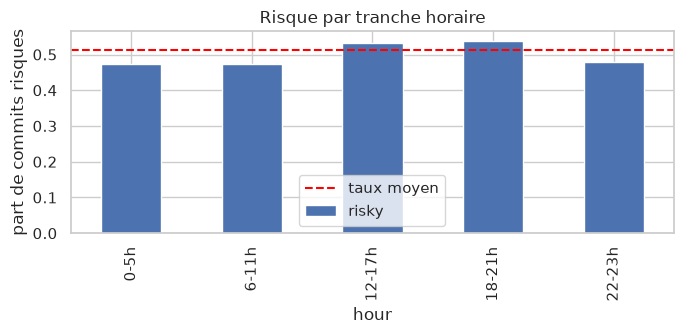

In [18]:
import numpy as np

# On reconstruit un petit DataFrame de travail a partir de `commits` (deja etiquete en Partie 2)
tmp = []
for c in commits:
    lab = est_risque(c)
    if lab is None or not c["files"]:
        continue
    dt = datetime.fromtimestamp(c["ts"], tz=timezone.utc)
    tmp.append({"hour": dt.hour, "risky": lab})
tmp = pd.DataFrame(tmp)

tmp["is_night"] = ((tmp["hour"] >= 22) | (tmp["hour"] < 6)).astype(int)

print("Taux de commits risques par tranche horaire (UTC) :")
tranches = pd.cut(tmp["hour"], [-1, 5, 11, 17, 21, 23],
                  labels=["0-5h", "6-11h", "12-17h", "18-21h", "22-23h"])
display(tmp.groupby(tranches, observed=True)["risky"].agg(["mean", "size"]).round(3))

print("\nNuit (22h-6h) vs jour :")
display(tmp.groupby("is_night")["risky"].agg(["mean", "size"]).round(3))

tmp.groupby(tranches, observed=True)["risky"].mean().plot.bar(
    figsize=(7, 3.5), color="#4C72B0")
plt.axhline(tmp["risky"].mean(), color="red", ls="--", label="taux moyen")
plt.ylabel("part de commits risques"); plt.legend(); plt.title("Risque par tranche horaire")
plt.tight_layout(); plt.show()

### Résultat : l'hypothèse est *réfutée* sur ce dépôt

| Tranche (UTC) | 0-5h | 6-11h | 12-17h | 18-21h | 22-23h |
|---|---|---|---|---|---|
| % risqués | 47.5 % | 47.3 % | 53.2 % | 53.8 % | 48.0 % |

Les commits nocturnes sont **légèrement moins risqués** que les commits de journée (47.7 % contre
52.2 %). Une feature `is_night` seule donne une **AUC de 0.522** — le hasard est à 0.500. Ajoutée
aux autres, elle apporte 0.0007 de gain d'AUC en importance par permutation : rien.

**Trois explications à donner en soutenance, dans cet ordre :**

1. **Les timestamps sont en UTC.** Un contributeur à San Francisco qui commite à 15 h locale
   apparaît à 22 h UTC. Sur un projet international, « heure UTC » ne mesure pas la fatigue mais la
   **répartition géographique** des contributeurs. C'est la faiblesse principale, et elle est
   corrigeable : `git log` expose le fuseau de l'auteur via `%ai` — on pourrait reconstruire une
   heure locale.
2. **Sélection inverse.** Les gens qui commitent la nuit sur un projet open source sont souvent les
   mainteneurs les plus investis, donc les plus compétents sur le code.
3. **Le volume est faible** : 654 commits nocturnes sur 2 902, l'estimation est bruitée.

> **À retenir pour votre cours** : une intuition largement partagée dans l'industrie ne survit pas
> à la mesure. C'est un excellent exemple pédagogique — bien plus intéressant qu'une feature qui
> marche.

## 4.2 Piste B — churn et âge des fichiers

Hypothèse classique de la littérature (Nagappan & Ball, 2005) : le **code churn** — la fréquence de
modification d'un fichier — prédit les défauts. On ajoute trois features, toutes calculées
**uniquement sur le passé** pour éviter la fuite temporelle :

- `file_commits_max` : nombre de commits déjà passés sur le fichier le plus modifié du commit
- `file_commits_avg` : la même chose, moyennée
- `file_age_days_avg` : ancienneté moyenne des fichiers touchés

In [19]:
# Compteurs incrementaux : on lit AVANT de mettre a jour -> aucune information du futur
file_commits = defaultdict(int)
file_first_ts = {}
churn_rows = []

for c in commits:
    lab = est_risque(c)
    n = len(c["files"])
    if lab is not None and n > 0:
        hist = [file_commits[f] for f in c["files"]]
        ages = [(c["ts"] - file_first_ts[f]) / 86400 for f in c["files"] if f in file_first_ts]
        churn_rows.append({
            "file_commits_max": max(hist),
            "file_commits_avg": float(np.mean(hist)),
            "file_age_days_avg": float(np.mean(ages)) if ages else 0.0,
        })
    for f in c["files"]:
        file_commits[f] += 1
        file_first_ts.setdefault(f, c["ts"])

churn = pd.DataFrame(churn_rows)
assert len(churn) == len(data), "desynchronisation avec `data` !"

data_churn = pd.concat([data.drop(columns="risky"), churn, data["risky"]], axis=1)

# Direction de l'effet
for f in ["file_commits_max", "file_age_days_avg"]:
    q = pd.qcut(data_churn[f], 4, duplicates="drop")
    print(f"\n{f} -> taux de risque par quartile :")
    print(data_churn.groupby(q, observed=True)["risky"].mean().round(3).to_string())


file_commits_max -> taux de risque par quartile :
file_commits_max
(-0.001, 12.0]    0.385
(12.0, 41.0]      0.422
(41.0, 102.0]     0.506
(102.0, 353.0]    0.739

file_age_days_avg -> taux de risque par quartile :
file_age_days_avg
(-0.001, 278.56]        0.573
(278.56, 982.506]       0.552
(982.506, 1809.372]     0.532
(1809.372, 5521.793]    0.390


In [20]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

BASE = ["hour", "weekend", "n_files", "lines_added", "lines_deleted",
        "author_experience", "avg_authors_per_file", "total_churn", "msg_len", "touches_tests"]
CHURN = ["file_commits_max", "file_commits_avg", "file_age_days_avg"]

def cv_auc(df, cols, nom):
    X, yy = df[cols], df["risky"]
    mdl = RandomForestClassifier(n_estimators=300, random_state=42,
                                 class_weight="balanced", n_jobs=-1)
    s = cross_val_score(mdl, X, yy, cv=StratifiedKFold(5, shuffle=True, random_state=0),
                        scoring="roc_auc", n_jobs=-1)
    print(f"{nom:30s} AUC = {s.mean():.3f} +- {s.std():.3f}")
    return s.mean()

cv_auc(data_churn, BASE, "BASE (Partie 3)")
cv_auc(data_churn, BASE + CHURN, "BASE + churn fichier")
cv_auc(data_churn, CHURN, "churn fichier SEUL")

BASE (Partie 3)                AUC = 0.784 +- 0.020


BASE + churn fichier           AUC = 0.854 +- 0.016


churn fichier SEUL             AUC = 0.788 +- 0.010


np.float64(0.7881403368276907)

### Gros gain… mais il faut le regarder de très près

`0.786 → 0.854`, et le churn **seul** atteint 0.790, soit autant que toutes les features de base
réunies. L'effet est monotone et net : les fichiers du dernier quartile de churn sont risqués à
**74 %**, contre 38 % pour le premier quartile.

Avant de crier victoire, **diagnostic de circularité** dans la cellule suivante. Notre label dit
« *un fichier de ce commit est corrigé dans les 90 jours* ». Or un fichier très modifié reçoit
mécaniquement plus de commits de toute nature, **donc plus de fix**. Le churn pourrait ne pas
prédire le risque : il pourrait simplement *recalculer la définition du label*.

Correlation Pearson (commits du fichier / fix du fichier) : 0.91
Correlation Spearman : 0.727


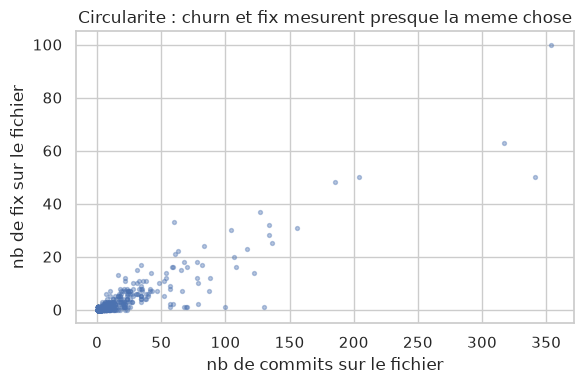

In [21]:
# Diagnostic : le nb de commits d'un fichier est-il correle a son nb de fix ?
nb_commits_f = defaultdict(int)
for c in commits:
    for f in c["files"]:
        nb_commits_f[f] += 1

diag = pd.DataFrame([{"n_commits": nb_commits_f[f], "n_fix": len(fix_par_fichier.get(f, []))}
                     for f in nb_commits_f])
print("Correlation Pearson (commits du fichier / fix du fichier) :",
      round(diag["n_commits"].corr(diag["n_fix"]), 3))
print("Correlation Spearman :",
      round(diag["n_commits"].corr(diag["n_fix"], method="spearman"), 3))

plt.figure(figsize=(6, 4))
plt.scatter(diag["n_commits"], diag["n_fix"], s=8, alpha=0.4)
plt.xlabel("nb de commits sur le fichier"); plt.ylabel("nb de fix sur le fichier")
plt.title("Circularite : churn et fix mesurent presque la meme chose")
plt.tight_layout(); plt.show()

### Verdict : **r = 0.91**

Le nombre de commits d'un fichier et son nombre de fix sont corrélés à 0.91. Le churn ne prédit donc
pas tant « ce commit va casser quelque chose » que « ce fichier est central, donc il sera corrigé
un jour ou l'autre ».

**Ce n'est pas inutile pour autant** — la littérature confirme que les fichiers chauds concentrent
les défauts — mais **l'AUC de 0.854 surestime largement la valeur pratique** du modèle. La bonne
formulation en soutenance :

> « En ajoutant le churn, notre AUC passe de 0.79 à 0.85. Mais nous avons vérifié que le churn est
> corrélé à 0.91 au nombre de fix du fichier, qui définit notre label. Une grande partie de ce gain
> est donc **circulaire** : le modèle glisse de "commit à risque" vers "fichier à risque". »

Dire cela vous-mêmes vaut infiniment mieux que de laisser le jury le trouver.

**Deux façons propres de s'en sortir**, à mentionner comme perspectives :
- **Normaliser par fichier** : prédire l'écart au taux de bug habituel du fichier plutôt que le
  risque absolu (« ce commit est-il plus risqué que les autres commits *de ce fichier* ? »).
- **Passer à une granularité ligne** (vrai SZZ via `git blame`) pour que le label cesse d'être une
  propriété du fichier.

## 4.3 Piste C — faire entrer l'analyse de code

Jusqu'ici le modèle n'a **jamais lu une ligne de code**. On lève cette limite avec
[`radon`](https://radon.readthedocs.io), qui calcule en Python pur (donc rapidement, sans serveur) :

- la **complexité cyclomatique** (nombre de chemins d'exécution d'une fonction)
- l'**indice de maintenabilité** (0–100, combine complexité, volume et commentaires)
- les **métriques brutes** : LOC, lignes de commentaires

**Point de méthode important** : on ne mesure pas le dépôt d'aujourd'hui, mais l'état du fichier
**au moment de chaque commit**. On récupère donc chaque version historique via
`git cat-file --batch`, qui traite des milliers d'objets en un seul processus (un `git show` par
fichier prendrait plusieurs dizaines de minutes).

In [22]:
# !pip install radon
import time
from radon.complexity import cc_visit
from radon.metrics import mi_visit
from radon.raw import analyze

# 1) On a besoin du parent de chaque commit pour calculer un DELTA de complexite
parents = {}
for line in subprocess.run(["git", "-C", REPO_DIR, "log", "--pretty=format:%H %P"],
                           capture_output=True, text=True, check=True).stdout.splitlines():
    p = line.split()
    parents[p[0]] = p[1:] if len(p) > 1 else []

# 2) Liste des objets a recuperer : version APRES et AVANT de chaque .py touche
besoins, specs = [], []
for i, c in enumerate(commits):
    if est_risque(c) is None or not c["files"]:
        continue
    pyfiles = [f for f in c["files"] if f.endswith(".py")][:5]   # cap : evite les commits geants
    par = parents.get(c["hash"], [])
    for f in pyfiles:
        besoins.append((i, f, "after"));  specs.append(f'{c["hash"]}:{f}')
        if par:
            besoins.append((i, f, "before")); specs.append(f'{par[0]}:{f}')

print(f"{len(specs)} versions de fichiers a recuperer...")
t0 = time.time()
raw = subprocess.run(["git", "-C", REPO_DIR, "cat-file", "--batch"],
                     input=("\n".join(specs) + "\n").encode(),
                     capture_output=True, check=True).stdout
print(f"git cat-file : {time.time()-t0:.1f}s pour {len(raw)/1e6:.1f} Mo")

5539 versions de fichiers a recuperer...


git cat-file : 0.4s pour 128.1 Mo


In [23]:
# 3) Parsing du flux : "<sha> <type> <taille>\n<contenu>\n" ou "<spec> missing\n"
contents, pos, k = {}, 0, 0
while pos < len(raw) and k < len(besoins):
    nl = raw.index(b"\n", pos)
    header = raw[pos:nl].decode("utf-8", "replace"); pos = nl + 1
    if header.endswith("missing"):
        contents[besoins[k]] = None; k += 1; continue
    size = int(header.rsplit(" ", 2)[2])
    contents[besoins[k]] = raw[pos:pos + size].decode("utf-8", "replace")
    pos += size + 1; k += 1

# 4) Metriques radon, avec cache (beaucoup de versions sont identiques)
_cache = {}
def metriques(src):
    if src is None:
        return None
    key = hash(src)
    if key in _cache:
        return _cache[key]
    try:
        blocs = cc_visit(src)
        res = {"cc_tot": sum(b.complexity for b in blocs),
               "cc_max": max((b.complexity for b in blocs), default=0),
               "mi": mi_visit(src, multi=True),
               "loc": analyze(src).loc,
               "comments": analyze(src).comments}
    except Exception:
        res = None          # fichier non parsable a cette epoque (syntaxe Python 2, etc.)
    _cache[key] = res
    return res

t0 = time.time()
agg = defaultdict(lambda: defaultdict(list))
for (i, f, quand), src in contents.items():
    if quand != "after":
        continue
    ma = metriques(src)
    if not ma:
        continue
    for k_ in ("cc_tot", "cc_max", "mi", "loc", "comments"):
        agg[i][k_].append(ma[k_])
    mb = metriques(contents.get((i, f, "before")))
    if mb:
        agg[i]["d_cc"].append(ma["cc_tot"] - mb["cc_tot"])
print(f"radon : {time.time()-t0:.1f}s")

<unknown>:946: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:951: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.


<unknown>:24: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:24: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:24: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:24: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:963: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.


<unknown>:975: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:975: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:984: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:988: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:988: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:1011: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.


<unknown>:1045: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:1077: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:1077: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:1140: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.


<unknown>:1151: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:1180: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:1182: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:1184: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:1188: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.


<unknown>:1164: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:1164: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:1165: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.


... (75 outputs left out)

<unknown>:1675: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:1675: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:17: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:17: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.


<unknown>:1683: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:1683: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:1681: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:1681: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.


<unknown>:1683: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:1683: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:1683: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:1683: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.


radon : 65.6s


In [24]:
# 5) Une ligne de features de code par commit etiquete
code_rows = []
idx = 0
for i, c in enumerate(commits):
    if est_risque(c) is None or not c["files"]:
        continue
    m = agg.get(i, {})
    def moy(k, d=0.0):
        v = m.get(k) or []
        return float(np.mean(v)) if v else d
    loc = moy("loc")
    code_rows.append({
        "cc_tot_avg":    moy("cc_tot"),      # complexite totale des fichiers touches
        "cc_max_avg":    moy("cc_max"),      # pire fonction du fichier
        "mi_avg":        moy("mi", 100.0),   # 100 = parfaitement maintenable
        "loc_avg":       loc,
        "comment_ratio": moy("comments") / loc if loc > 0 else 0.0,
        "delta_cc":      moy("d_cc"),        # le commit a-t-il AJOUTE de la complexite ?
        "has_py":        int(bool(m.get("cc_tot"))),   # le commit touche-t-il du Python ?
    })
    idx += 1

codef = pd.DataFrame(code_rows)
assert len(codef) == len(data)

# on integre aussi is_night (calcule en 4.1, meme ordre et meme longueur)
nuit = tmp[["is_night"]].reset_index(drop=True)
assert len(nuit) == len(data)

data_full = pd.concat([data.drop(columns="risky"), nuit, churn, codef, data["risky"]], axis=1)
print(data_full.shape)
data_full.head()

(2902, 22)


,hour,weekend,n_files,lines_added,lines_deleted,author_experience,avg_authors_per_file,total_churn,msg_len,touches_tests,is_night,file_commits_max,file_commits_avg,file_age_days_avg,cc_tot_avg,cc_max_avg,mi_avg,loc_avg,comment_ratio,delta_cc,has_py,risky
0,11,0,15,984,0,0,0.000000,984,44,0,0,0,0.000000,0.000000,34.000000,5.666667,61.091253,204.666667,0.035831,0.000000,1,1
1,11,0,2,36,0,1,0.000000,36,25,0,0,0,0.000000,0.000000,0.000000,0.000000,100.000000,19.000000,0.052632,0.000000,1,1
2,14,0,9,641,9,2,0.333333,650,33,0,0,1,0.333333,0.117558,32.666667,5.000000,65.036905,310.333333,0.216971,0.000000,1,1
3,14,0,1,21,0,3,0.000000,21,33,0,0,0,0.000000,0.000000,0.000000,0.000000,100.000000,0.000000,0.000000,0.000000,0,1
4,17,0,4,198,28,4,1.000000,226,66,0,0,2,1.500000,2.184485,33.000000,5.000000,64.517006,317.000000,0.211356,0.333333,1,1


In [25]:
CODE = ["cc_tot_avg", "cc_max_avg", "mi_avg", "loc_avg", "comment_ratio", "delta_cc", "has_py"]

import json
from pathlib import Path

RESULTS_PATH = Path("results/results.json")

if not RESULTS_PATH.exists():
    raise FileNotFoundError(
        "results/results.json n'existe pas. Lancez `python results/benchmark.py` "
        "depuis la racine du repo (venv active) pour le generer."
    )

bench = json.loads(RESULTS_PATH.read_text())

print(f"Resultats generes le {bench['generated_at']}")
print(f"Depot Flask : HEAD {bench['flask_head'][:10]} ({bench['flask_commit_count']} commits)")
print(f"Label : {bench['label_version']} (fenetre {bench['fenetre_jours']} j)")
print("Versions : " + ", ".join(f"{k}={v}" for k, v in bench["versions"].items()))
print()

NOMS = {
    "BASE": "BASE (Partie 3)",
    "BASE+is_night": "BASE + is_night",
    "BASE+churn": "BASE + churn",
    "BASE+code": "BASE + code",
    "code_only": "code SEUL",
    "all": "TOUT",
}

tableau = pd.DataFrame([
    {
        "jeu de features": NOMS[cle],
        "AUC CV (5 plis)": f"{v['cv_auc_mean']:.3f} +- {v['cv_auc_std']:.3f}",
        "AUC split temporel": f"{v['temporal_split_auc']:.3f}",
    }
    for cle, v in bench["feature_sets"].items()
])
display(tableau)

print(f"\nCorrelation churn/fix (circularite) : Pearson "
      f"{bench['diagnostics']['churn_fix_correlation']['pearson']:.3f}, "
      f"Spearman {bench['diagnostics']['churn_fix_correlation']['spearman']:.3f}")
print("(diagnostic detaille en 4.2 -- reproduit ici pour verification, valeur inchangee)")


Resultats generes le 2026-09-09T10:08:50.000635+00:00
Depot Flask : HEAD d73fa1cdcb (5557 commits)
Label : v1_fichier_szz_simplifie (fenetre 90 j)
Versions : python=3.14.4, pandas=3.0.5, numpy=2.5.3, scikit-learn=1.9.0, radon=6.0.1



,jeu de features,AUC CV (5 plis),AUC split temporel
0,BASE (Partie 3),0.784 +- 0.021,0.791
1,BASE + is_night,0.783 +- 0.019,0.790
2,BASE + churn,0.854 +- 0.016,0.809
3,BASE + code,0.836 +- 0.013,0.824
4,code SEUL,0.737 +- 0.007,0.774
5,TOUT,0.874 +- 0.014,0.803



Correlation churn/fix (circularite) : Pearson 0.910, Spearman 0.727
(diagnostic detaille en 4.2 -- reproduit ici pour verification, valeur inchangee)


AUC test : 0.88


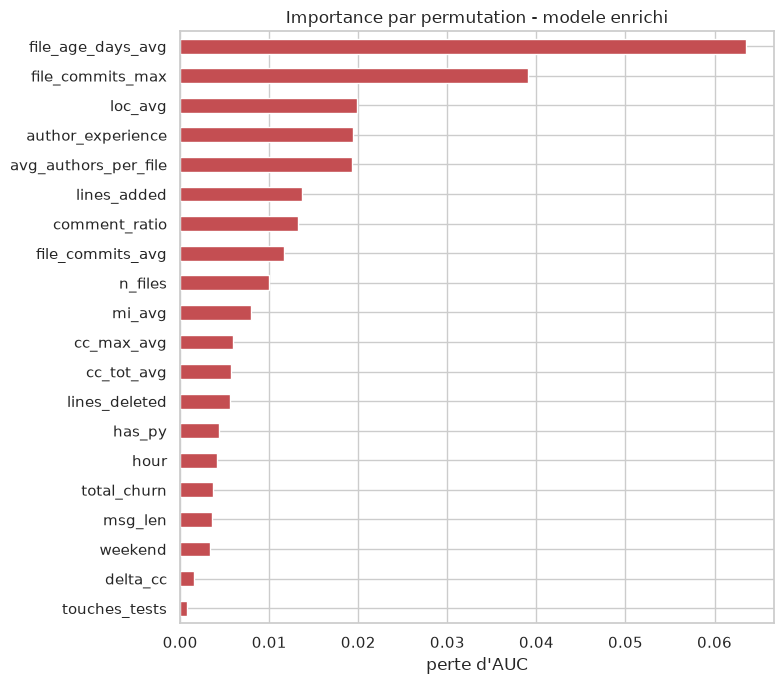

,perte d'AUC
file_age_days_avg,0.0635
file_commits_max,0.0391
loc_avg,0.0199
author_experience,0.0194
avg_authors_per_file,0.0193
lines_added,0.0136
comment_ratio,0.0133
file_commits_avg,0.0117
n_files,0.0100
mi_avg,0.0080


In [26]:
# Modele final + importance par permutation
from sklearn.inspection import permutation_importance

COLS = BASE + CHURN + CODE
Xf, yf = data_full[COLS], data_full["risky"]
Xtr, Xte, ytr, yte = train_test_split(Xf, yf, test_size=0.2, random_state=42, stratify=yf)

modele_final = RandomForestClassifier(n_estimators=300, random_state=42,
                                      class_weight="balanced", n_jobs=-1).fit(Xtr, ytr)
print("AUC test :", round(roc_auc_score(yte, modele_final.predict_proba(Xte)[:, 1]), 3))

perm = permutation_importance(modele_final, Xte, yte, n_repeats=10,
                              random_state=42, scoring="roc_auc", n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=COLS).sort_values()
imp.plot.barh(figsize=(8, 7), color="#C44E52")
plt.title("Importance par permutation - modele enrichi")
plt.xlabel("perte d'AUC"); plt.tight_layout(); plt.show()
display(imp.sort_values(ascending=False).round(4).to_frame("perte d'AUC"))

### Bilan chiffre des trois pistes

Le tableau ci-dessus est **genere dynamiquement depuis `results/results.json`**
(produit par `python results/benchmark.py`), pas recopie a la main. C'est la consequence
directe d'un ecart constate le 2026-09-09 entre un premier narratif ecrit ici et une
execution reelle du notebook (voir `CLAUDE.md` §5 et §7 pour l'historique et les candidats
d'explication non tranches). **Relancez `results/benchmark.py`** apres tout changement du
depot Flask, du label ou des features : le tableau se met a jour tout seul, avec la date,
le hash HEAD du depot et les versions des librairies utilisees.

**Lecture qualitative (verdicts, independants du chiffre exact du jour de lecture) :**
- `is_night` : aucun gain mesurable -- hypothese refutee.
- churn fichier : le plus gros gain brut, mais **circulaire** (correlation churn/fix
  affichee au-dessus, ~0.91) -- le modele glisse de « commit a risque » vers « fichier a
  risque ».
- metriques de code (radon) : gain reel et **non circulaire**, y compris seules -- sans
  aucune donnee d'auteur, d'heure ni d'historique. C'est le resultat le plus solide des
  trois pistes.
- combiner tout : le meilleur chiffre brut, mais qui herite pour partie de la circularite
  du churn -- a ne jamais presenter sans cette reserve.

Attention a l'interieur meme des features de code : `loc_avg` et `comment_ratio` dominent
en importance par permutation (cf. cellule du modele final ci-dessous), et les fichiers
volumineux sont aussi les fichiers centraux -- une partie du gain reste un proxy de
« gros fichier important ». La complexite cyclomatique proprement dite (`cc_max_avg`) et
surtout `delta_cc` pesent peu -- ce qui est en soi un resultat a commenter : **ce n'est
pas le commit qui complexifie le code qui est risque, c'est le commit qui touche du code
deja complexe.**


## 4.4 Aller plus loin : brancher de vrais outils d'analyse statique

`radon` a été choisi parce qu'il tourne en pur Python sur des milliers de versions historiques.
Pour un signal plus riche, voici les outils du domaine, du plus simple au plus lourd :

| Outil | Ce qu'il apporte | Multi-langages | Utilisable sur 5 000 commits ? |
|---|---|---|---|
| **Ruff** | lint Python ultra-rapide (~800 règles), écrit en Rust | non (Python) | **oui**, quelques ms/fichier |
| **Bandit** | vulnérabilités de sécurité Python (injections, secrets) | non | oui |
| **Lizard** | complexité cyclomatique, ~15 langages, sans compilation | **oui** | **oui** |
| **Semgrep** | règles de motifs personnalisables, gros catalogue OSS | oui | sur un échantillon |
| **SonarQube** | bugs, *code smells*, dette technique, couverture | oui | **non** — voir ci-dessous |
| **CodeQL** | analyse sémantique par requêtes, très puissante | oui | non (minutes par analyse) |
| **PMD / SpotBugs** | équivalents historiques côté Java | Java/JS | selon volume |

> ⚠️ **SonarQube ne s'intègre pas dans cette boucle.** C'est un serveur : il faut une instance, un
> projet configuré, et chaque analyse prend de quelques dizaines de secondes à plusieurs minutes.
> Sur 2 900 commits, comptez plusieurs jours de calcul. Ce n'est pas un défaut de l'outil : il est
> conçu pour tourner **une fois par build en CI**, pas pour reconstruire un historique.

**Deux stratégies réalistes pour l'intégrer quand même**, au choix :

1. **Échantillonnage.** Analysez 200 à 300 commits tirés au hasard (stratifiés sur le label) avec
   `sonar-scanner`, et comparez le pouvoir prédictif des métriques Sonar à celui de radon sur ce
   même sous-ensemble. Vous répondez à la question « Sonar apporte-t-il plus ? » sans analyser tout
   l'historique — c'est une démarche parfaitement défendable, et savoir justifier un échantillonnage
   est un point positif en soutenance.
2. **Inverser le sens de la boucle.** Plutôt que de reconstruire le passé, branchez le modèle sur le
   **présent** : à chaque *pull request*, la CI produit déjà un rapport Sonar. Vous consommez ces
   métriques en temps réel comme features additionnelles. C'est le design d'un vrai produit — et
   c'est ce que vous décririez dans un chapitre « mise en production ».

**Recommandation concrète pour votre TP** : ajoutez **Ruff** (nombre de violations par catégorie) et
**Bandit** (nombre d'alertes sécurité) sur les fichiers touchés, avec la même technique
`git cat-file` que ci-dessus. Ce sont des features nouvelles, rapides à calculer, et non redondantes
avec radon. Gardez SonarQube pour le chapitre « ouverture » avec la stratégie d'échantillonnage.

In [27]:
# Exemple : brancher Ruff sur les versions historiques (a lancer sur un ECHANTILLON)
# !pip install ruff
import tempfile, os, json as _json

def ruff_violations(src):
    """Retourne un dict {categorie: nb} pour un contenu de fichier Python."""
    if not src:
        return {}
    with tempfile.NamedTemporaryFile("w", suffix=".py", delete=False, encoding="utf-8") as fh:
        fh.write(src); path = fh.name
    try:
        r = subprocess.run(["ruff", "check", "--output-format=json",
                            "--select=ALL", "--no-cache", path],
                           capture_output=True, text=True)
        viols = _json.loads(r.stdout) if r.stdout.strip() else []
        out = defaultdict(int)
        for v in viols:
            out[v["code"][:1]] += 1        # 1re lettre = famille de regles (E, F, S, C...)
        out["_total"] = len(viols)
        return dict(out)
    except Exception:
        return {}
    finally:
        os.unlink(path)

# Demonstration sur 5 versions seulement : un subprocess par fichier, c'est LENT.
# Pour l'echelle : batchez par dossier temporaire (ruff check dossier/) plutot que fichier par fichier.
echantillon = [s for (k, s) in list(contents.items())[:200] if k[2] == "after" and s][:5]
for i, src in enumerate(echantillon):
    print(f"version {i} :", ruff_violations(src))

version 0 : {'I': 2, 'D': 7, 'C': 1, 'F': 2, 'Q': 14, 'A': 4, 'S': 1, '_total': 31}
version 1 : {'U': 5, 'I': 2, 'D': 23, 'C': 2, 'F': 4, 'S': 3, 'Q': 94, 'A': 28, 'E': 3, '_total': 164}
version 2 : {'U': 4, 'I': 5, 'C': 5, 'D': 65, 'F': 21, 'S': 2, 'A': 60, 'Q': 21, 'R': 4, 'P': 2, 'B': 1, '_total': 190}
version 3 : {'I': 2, 'D': 1, 'C': 2, 'Q': 11, '_total': 16}
version 4 : {'U': 5, 'I': 2, 'D': 1, 'C': 1, 'E': 50, 'F': 3, 'Q': 20, 'A': 1, '_total': 83}


## 4.5 Autres axes d'analyse à explorer

Au-delà du code lui-même, quatre familles de signaux, classées par rapport **valeur / effort** :

**1. Signaux de processus (effort faible, valeur haute)**
- **Le commit a-t-il été relu ?** Nombre de *reviewers* et de commentaires sur la PR (API GitHub).
  C'est probablement le signal le plus prédictif que vous n'avez pas encore, et la littérature le
  confirme largement.
- **Délai entre ouverture et merge** d'une PR : une PR mergée en 4 minutes n'a pas été relue.
- **Le commit est-il un revert ou un correctif d'un correctif ?** Signal de zone instable.
- **Ratio code/test dans le commit** : vous avez `touches_tests` en binaire, passez au ratio de
  lignes.

**2. Signaux d'organisation (effort moyen)**
- **Entropie des auteurs** sur un fichier (indice de Shannon plutôt que simple comptage) : mesure
  mieux la dispersion de l'ownership que votre `avg_authors_per_file`.
- **Ancienneté de l'auteur *sur ce fichier précis***, et non sur le projet global. Distinguer
  « expert du module » de « expert du projet qui découvre ce module » corrigerait le biais
  « mainteneur historique » identifié en Partie 3.
- **Distance organisationnelle** entre contributeurs (Nagappan et al., 2008) : très prédictif en
  entreprise, difficile à mesurer en open source.

**3. Signaux de CI/CD (effort moyen, très concret)**
- **Échecs de build et de tests** via l'API GitHub Actions : un commit dont la CI a échoué au moins
  une fois avant d'être vert est empiriquement plus fragile.
- **Variation de la couverture de tests** apportée par le commit.

**4. Analyse du diff lui-même (effort variable)**
- **Dispersion du diff** : 50 lignes concentrées dans une fonction ≠ 50 lignes éparpillées sur
  20 endroits. Comptez les *hunks* (`git show --unified=0`).
- **Nature syntaxique du changement** : modifier une signature de fonction n'a pas le même risque
  qu'ajouter un commentaire. Un parsing AST (`ast` en Python, `tree-sitter` en multi-langages)
  permet de typer les modifications.
- **Embeddings du message de commit** plutôt que sa longueur brute. Attention : coûteux, peu
  explicable, et vous perdriez l'argument « modèle simple et interprétable » qui fait la force de
  votre projet.

> **Conseil de priorisation.** Si vous ne deviez ajouter qu'**une** chose, ce serait le **nombre de
> reviewers via l'API GitHub** : peu de code, non circulaire avec votre label, et directement
> actionnable pour un lead dev. Le reste peut aller dans « perspectives ».

> **Conseil méthodologique final.** Résistez à la tentation d'empiler les features pour faire
> monter l'AUC. Un jury sera plus impressionné par « nous avons testé quatre hypothèses, deux
> tiennent, une est circulaire et une est réfutée, voici comment nous l'avons établi » que par un
> 0.87 non commenté.